# 3. Naloxone and naltrexone: exploratory profile comparison

**RQ1b:** At which MOR positions and substitutions do naloxone and naltrexone differ despite high chemical similarity and similar WT TRUPATH Emax estimates?

## 3.1 Inputs and matched missense cohort

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "pyproject.toml").is_file()
     and (path / "data/raw").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate project root.")

RAW_DATA_DIR = PROJECT_ROOT / "data/raw"
PROFILE_PATH = (
    PROJECT_ROOT
    / "results/01_reproduce_ligand_profiles/position_mean_effects.csv"
)
LIGANDS = ["Naloxone", "Naltrexone"]
N_TOP_POSITIONS = 10
N_CANDIDATE_VARIANTS = 12
AMINO_ACID_ORDER = list("AVLIMFWY") + list("STNQCGP") + list("DEKRH")

variants = pd.read_csv(RAW_DATA_DIR / "01_variant_scores.csv", low_memory=False)
ligand_info = pd.read_csv(RAW_DATA_DIR / "05_ligand_summary.csv")
effect_cols = [f"{ligand}_effect" for ligand in ligand_info["ligand"]]

cohort = variants.loc[
    variants["type"].eq("missense")
    & variants["position"].between(65, 355)
].dropna(subset=effect_cols).copy()
cohort["position"] = cohort["position"].astype(int)
cohort["delta"] = cohort["Naloxone_effect"] - cohort["Naltrexone_effect"]

assert len(effect_cols) == 15
assert len(cohort) == 5519
assert cohort["hgvs"].notna().all() and cohort["hgvs"].is_unique
assert np.isfinite(cohort[effect_cols].to_numpy()).all()

annotations = (
    cohort[["position", "wildtype", "SSE", "GPCRdb"]]
    .drop_duplicates()
    .set_index("position")
    .sort_index()
)
assert annotations.index.is_unique

pair_profiles = (
    pd.read_csv(PROFILE_PATH, index_col="position")
    .loc[:, LIGANDS]
    .sort_index()
)
assert pair_profiles.index.is_unique
assert np.array_equal(pair_profiles.index, np.arange(65, 356))
assert np.isfinite(pair_profiles.to_numpy()).all()
pair_profiles.index = pair_profiles.index.astype(int)

recomputed_profiles = cohort.groupby("position")[[f"{x}_effect" for x in LIGANDS]].mean()
np.testing.assert_allclose(
    pair_profiles.to_numpy(), recomputed_profiles.to_numpy(),
    rtol=0, atol=1e-12,
)
print(f"Validated {len(cohort):,} missense variants across {len(pair_profiles)} positions.")
display(ligand_info.set_index("ligand").loc[
    LIGANDS, ["tp_emax", "tp_emax_sem", "tp_n"]
])

Validated 5,519 missense variants across 291 positions.


,tp_emax,tp_emax_sem,tp_n
ligand,,,
Naloxone,14.9,7.4,6.0
Naltrexone,15.0,7.9,6.0


## 3.2 Position-level differences and receptor regions

Define `delta = Naloxone - Naltrexone` and rank positions by its absolute value, retaining the sign and both ligand means. The top 10 is a descriptive selection rather than a significance threshold; these normalized effects are not absolute activity or efficacy.

In [2]:
pair_profiles["delta"] = pair_profiles["Naloxone"] - pair_profiles["Naltrexone"]
pair_profiles["abs_delta"] = pair_profiles["delta"].abs()
position_view = pair_profiles.join(annotations)
top_positions = position_view.nlargest(N_TOP_POSITIONS, "abs_delta").copy()

print(f"Profile Pearson r: {pair_profiles[LIGANDS].corr().iloc[0, 1]:.6f}")
display(top_positions[["wildtype", "SSE", *LIGANDS, "delta", "abs_delta"]])

Profile Pearson r: 0.718418


,wildtype,SSE,Naloxone,Naltrexone,delta,abs_delta
position,,,,,,
177,A,ICL2,0.058087,-0.065133,0.123220,0.123220
66,S,N-tail,-0.063181,0.050013,-0.113193,0.113193
253,C,TM5,-0.000267,-0.111934,0.111668,0.111668
151,Y,TM3,0.192503,0.086571,0.105932,0.105932
168,Y,TM3,0.038351,-0.063007,0.101359,0.101359
94,V,TM1,-0.086880,0.010780,-0.097660,0.097660
185,N,TM4,-0.123572,-0.028781,-0.094791,0.094791
294,C,TM6,0.048560,-0.044746,0.093306,0.093306
285,L,TM6,0.018992,-0.073833,0.092825,0.092825


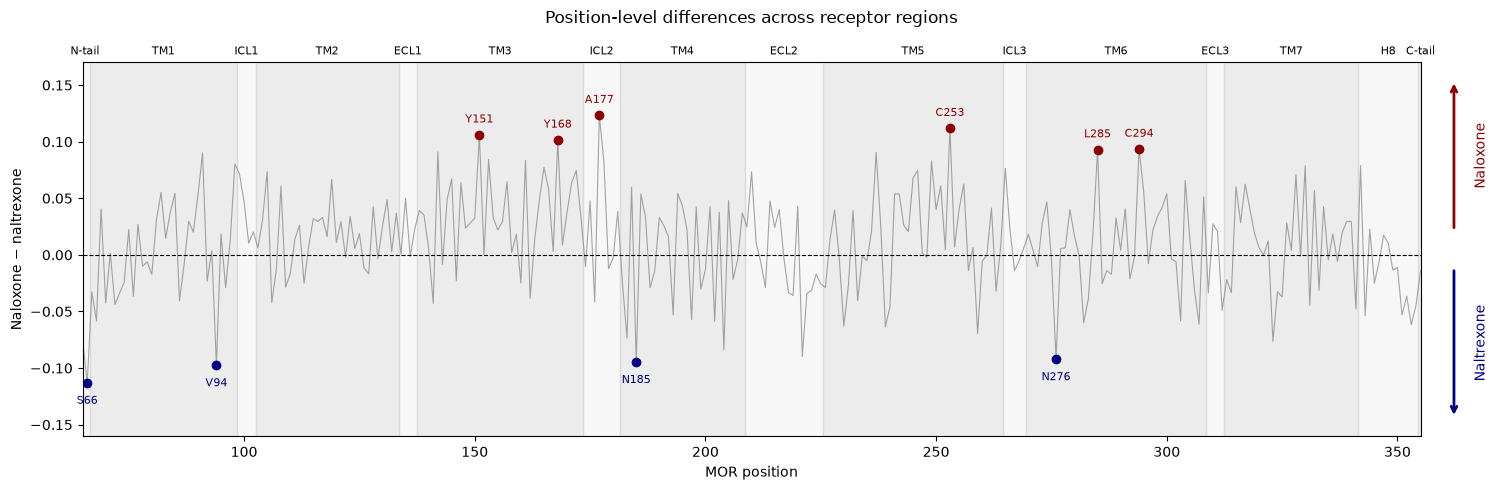

In [ ]:
fig, ax = plt.subplots(figsize=(15, 5))

# Shade consecutive secondary-structure segments.
segments = position_view["SSE"].ne(
    position_view["SSE"].shift()
).cumsum()

for segment_id, block in position_view.groupby(segments):
    start, end = block.index.min(), block.index.max()

    ax.axvspan(
        start - 0.5, end + 0.5,
        color="gray",
        alpha=0.06 if segment_id % 2 else 0.15,
    )
    ax.text(
        (start + end) / 2, 1.02,
        str(block["SSE"].iloc[0]),
        transform=ax.get_xaxis_transform(),
        ha="center", fontsize=8,
    )

ax.plot(
    position_view.index, position_view["delta"],
    color="gray", linewidth=0.8, alpha=0.7,
)

for position, row in top_positions.iterrows():
    color = "darkred" if row["delta"] > 0 else "navy"
    ax.scatter(position, row["delta"], color=color, zorder=3)
    ax.annotate(
        f"{row['wildtype']}{int(position)}",
        (position, row["delta"]),
        xytext=(0, 9 if row["delta"] > 0 else -15),
        textcoords="offset points",
        ha="center", fontsize=8, color=color,
    )

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.set(
    xlabel="MOR position",
    ylabel="Naloxone - naltrexone",
    title="Position-level differences across receptor regions",
    xlim=(65, 355),
)
ax.set_title("Position-level differences across receptor regions", pad=28)
ax.margins(y=0.2)

ax.annotate(
    "", xy=(1.025, 0.95), xytext=(1.025, 0.55),
    xycoords="axes fraction",
    arrowprops=dict(arrowstyle="->", color="darkred", lw=2),
    annotation_clip=False,
)
ax.text(
    1.045, 0.75, "Naloxone",
    transform=ax.transAxes,
    rotation=90, ha="center", va="center", color="darkred",
)

ax.annotate(
    "", xy=(1.025, 0.05), xytext=(1.025, 0.45),
    xycoords="axes fraction",
    arrowprops=dict(arrowstyle="->", color="navy", lw=2),
    annotation_clip=False,
)
ax.text(
    1.045, 0.25, "Naltrexone",
    transform=ax.transAxes,
    rotation=90, ha="center", va="center", color="navy",
)

fig.tight_layout()
plt.show()

## 3.3 Substitution patterns at the selected positions

Compare signed variant-level differences across the top positions to distinguish broad patterns from a few extreme substitutions. Gray cells are unobserved missense entries, including the unchanged wild-type amino acid; colors do not encode uncertainty.

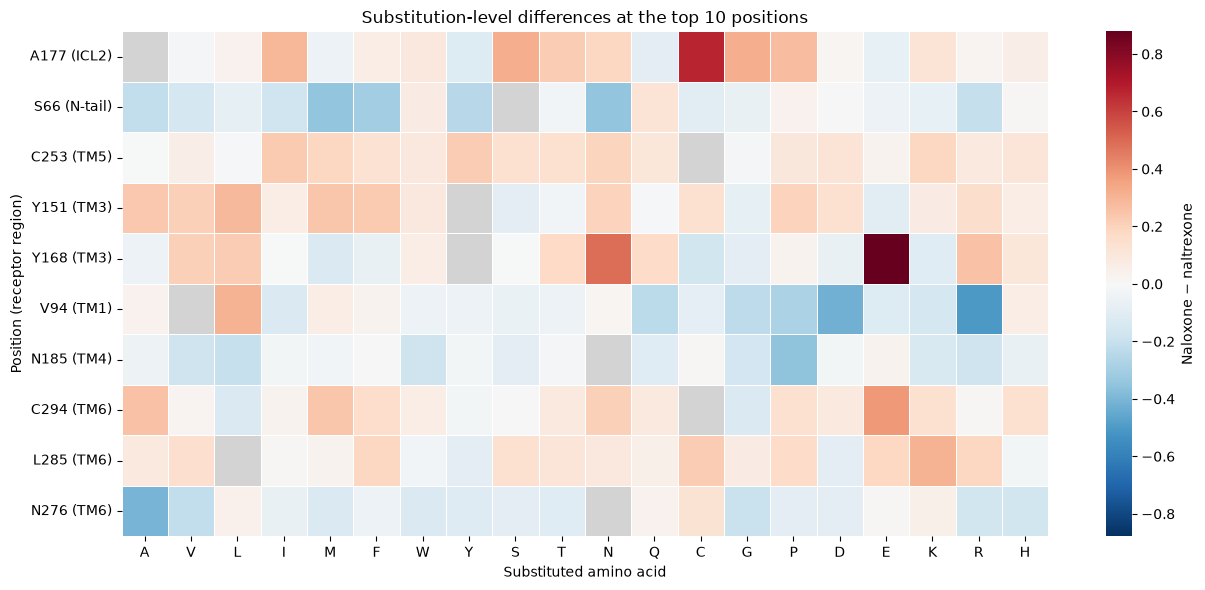

In [ ]:
selected = cohort.loc[
    cohort["position"].isin(top_positions.index)
].copy()

delta_map = (
    selected.pivot(
        index="position", columns="mutation", values="delta"
    )
    .reindex(
        index=top_positions.index,
        columns=AMINO_ACID_ORDER,
    )
)

delta_map.index = [
    f"{annotations.loc[position, 'wildtype']}{int(position)}"
    f" ({annotations.loc[position, 'SSE']})"
    for position in delta_map.index
]

selected_delta_limit = np.nanmax(np.abs(delta_map.to_numpy()))

fig, ax = plt.subplots(figsize=(13, 6))

sns.heatmap(
    delta_map,
    cmap="RdBu_r",
    center=0,
    vmin=-selected_delta_limit,
    vmax=selected_delta_limit,
    linewidths=0.5,
    ax=ax,
    cbar_kws={"label": "Naloxone - naltrexone"},
)

ax.set_facecolor("lightgray")
ax.set(
    xlabel="Substituted amino acid",
    ylabel="Position (receptor region)",
    title="Substitution-level differences at the top 10 positions",
)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
plt.show()

## 3.4 Surface-expression context

Plot each variant difference against its surface-expression effect, using common axes across positions and reporting missing expression measurements. This is descriptive context, not an expression adjustment or a filter; proximity to zero does not establish unchanged expression.

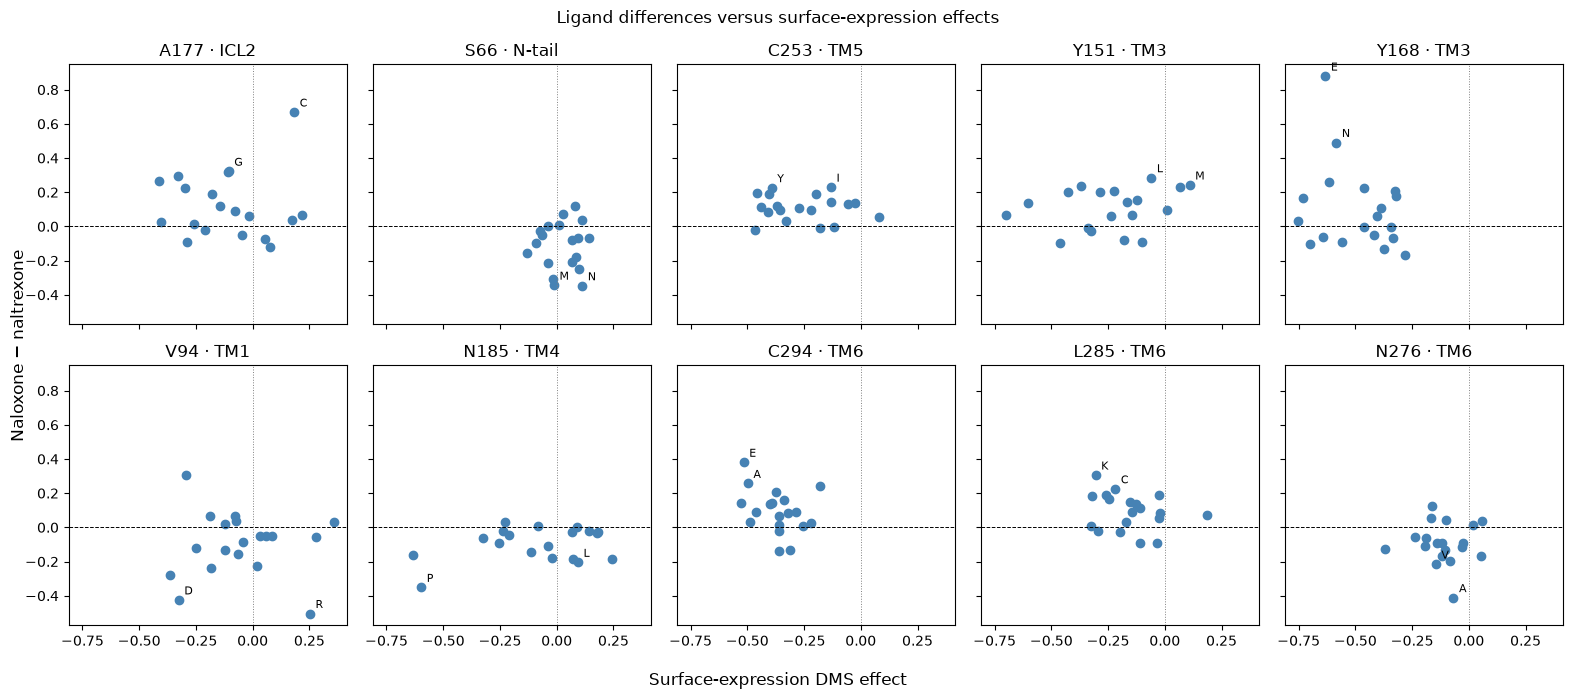

Variants omitted because of missing expression: 0


In [ ]:
fig, axes = plt.subplots(
    2, 5, figsize=(16, 7), sharex=True, sharey=True
)

for ax, position in zip(axes.flat, top_positions.index):
    group = selected.loc[selected["position"].eq(position)]
    complete = group.dropna(subset=["surface_effect", "delta"])

    ax.scatter(
        complete["surface_effect"],
        complete["delta"],
        color="steelblue",
    )

    # Label the two largest differences at each position.
    labels = complete["delta"].abs().nlargest(2).index
    for idx in labels:
        row = complete.loc[idx]
        ax.annotate(
            row["mutation"],
            (row["surface_effect"], row["delta"]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

    ax.axhline(0, color="black", linestyle="--", linewidth=0.7)
    ax.axvline(0, color="gray", linestyle=":", linewidth=0.7)

    wildtype = annotations.loc[position, "wildtype"]
    region = annotations.loc[position, "SSE"]
    ax.set_title(f"{wildtype}{int(position)} · {region}")

fig.supxlabel("Surface-expression DMS effect")
fig.supylabel("Naloxone - naltrexone")
fig.suptitle("Ligand differences versus surface-expression effects")
fig.tight_layout()
plt.show()

print(
    "Variants omitted because of missing expression:",
    selected["surface_effect"].isna().sum(),
)

## 3.5 Uncertainty of the largest variant differences

Inspect the 12 largest absolute variant differences within the selected positions alongside each ligand's ±1 SE. These are not confidence intervals for delta: the covariance between ligand estimates is unavailable, and overlap of the bars is not a test of the difference.

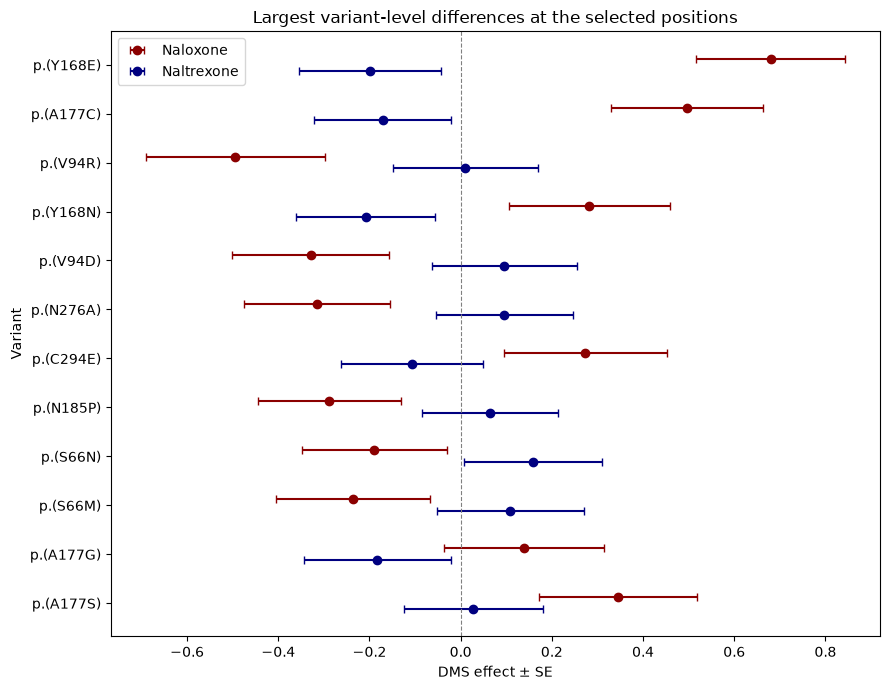

In [6]:
candidate_variants = (
    selected
    .assign(abs_delta=lambda df: df["delta"].abs())
    .nlargest(N_CANDIDATE_VARIANTS, "abs_delta")
    .reset_index(drop=True)
)

y = np.arange(len(candidate_variants))

fig, ax = plt.subplots(figsize=(9, 7))

for offset, ligand, color in [
    (-0.12, "Naloxone", "darkred"),
    (0.12, "Naltrexone", "navy"),
]:
    ax.errorbar(
        candidate_variants[f"{ligand}_effect"],
        y + offset,
        xerr=candidate_variants[f"{ligand}_effect_se"],
        fmt="o",
        capsize=3,
        color=color,
        label=ligand,
    )

ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_yticks(y, candidate_variants["hgvs"])
ax.invert_yaxis()
ax.set(
    xlabel="DMS effect ± SE",
    ylabel="Variant",
    title="Largest variant-level differences at the selected positions",
)
ax.legend()

fig.tight_layout()
plt.show()

## 3.6 Local context around Y168 and A177

Examine every available substitution at positions 160–185, including neighbors outside the top 10, because Y168 and A177 emerged from the preceding exploration. This post hoc sequence window shows local patterns but does not establish spatial proximity or enrichment.

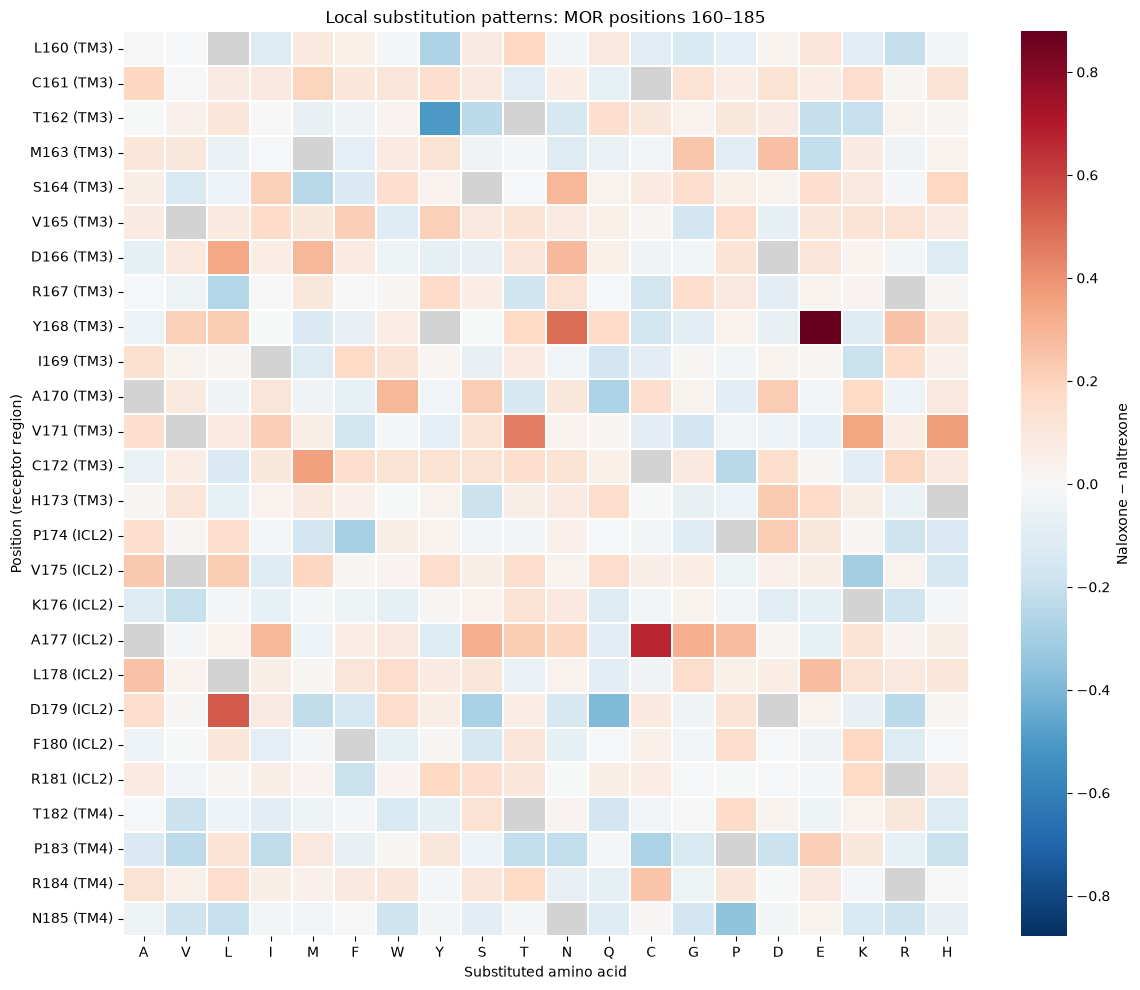

In [ ]:
local_variants = cohort.loc[
    cohort["position"].between(160, 185)
].copy()

local_map = (
    local_variants.pivot(
        index="position", columns="mutation", values="delta"
    )
    .reindex(columns=AMINO_ACID_ORDER)
    .sort_index()
)

local_map.index = [
    f"{annotations.loc[pos, 'wildtype']}{int(pos)}"
    f" ({annotations.loc[pos, 'SSE']})"
    for pos in local_map.index
]

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    local_map,
    cmap="RdBu_r",
    center=0,
    vmin=-selected_delta_limit,
    vmax=selected_delta_limit,
    linewidths=0.3,
    ax=ax,
    cbar_kws={"label": "Naloxone - naltrexone"},
)
ax.set_facecolor("lightgray")
ax.set(
    xlabel="Substituted amino acid",
    ylabel="Position (receptor region)",
    title="Local substitution patterns: MOR positions 160–185",
)

fig.tight_layout()
plt.show()